# Transformers are SSMs: Generalized Models and Efficient Algorithms Through Structured State Space Duality (Mamba-2)

**Paper:** [arXiv:2405.21060](https://arxiv.org/abs/2405.21060)
**Authors:** Tri Dao, Albert Gu (2024; ICML 2024)

This notebook implements the core **Structured State Space Duality (SSD)** layer from Listing 1 of the Mamba-2 paper in pure PyTorch. It demonstrates:
1. The **quadratic (attention-like) form** of SSD - showing that a selective SSM is masked attention with a 1-semiseparable mask
2. The **block-decomposed (chunked) form** from Listing 1 - combining matmul-friendly diagonal blocks with a smaller recurrence
3. **Numerical verification** that the two forms produce identical outputs (the duality)
4. A comparison of **SSD vs. linear attention** on a synthetic multi-query associative recall (MQAR) task


## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# Hyperparameters (Section 7 / 9 of the paper, scaled down for a toy task)
SEQ_LEN    = 64    # sequence length (paper: up to 16K)
D_MODEL    = 64     # model dimension (paper: 2560 for 2.7B)
D_STATE    = 64     # state expansion N (paper: 64-256)
D_HEAD     = 16     # head dimension P (paper: 64-128)
N_HEADS    = 4      # number of heads = D_MODEL // D_HEAD
CHUNK_SIZE = 64     # block size Q for chunked SSD (paper: 64-128)
N_LAYERS   = 2      # number of SSD blocks (paper: 48+)
VOCAB_SIZE = 16     # vocab for MQAR task
EPOCHS     = 15
LR         = 1e-3
BATCH_SIZE = 64
N_TRAIN    = 4000
N_VAL      = 500

print(f'Config: seq_len={SEQ_LEN}, d_model={D_MODEL}, d_state={D_STATE}, '
      f'd_head={D_HEAD}, n_heads={N_HEADS}, chunk={CHUNK_SIZE}, layers={N_LAYERS}')


Device: cpu
Config: seq_len=64, d_model=64, d_state=64, d_head=16, n_heads=4, chunk=64, layers=2


## 2. Data - Multi-Query Associative Recall (MQAR)

The paper highlights MQAR (Section 9.1, Figure 8) as a key task: the model must memorize several key-value pairs
scattered through a sequence, then recall the correct value when a query key reappears later. This tests the
model's ability to store and retrieve information in its recurrent state - exactly what SSD's larger state
size N is designed for.

We generate synthetic MQAR sequences following the format from Arora et al. (2024): each sequence packs
4 key-value pairs at the start, followed by 4 query tokens, with the rest as padding (token 0). The model
must predict the correct value at each query position.


In [2]:
def generate_mqar_batch(batch_size, seq_len, vocab_size=16, n_kv_pairs=4, seed=None):
    """Generate Multi-Query Associative Recall (MQAR) sequences.
    
    Layout per sequence: [k1 v1 k2 v2 ... kn vn  q1 q2 ... qm  <pad...>]
    where ki, vi, qi are tokens from vocab. The target for each query qi
    is the value vi that was paired with key ki earlier in the sequence.
    This follows the MQAR format used in Arora et al. (2024) and the
    Mamba-2 paper (Section 9.1, Figure 8).
    
    Returns:
        x: (batch, seq_len) int tokens
        y: (batch, seq_len) int targets (-100 at non-query positions for loss masking)
    """
    gen = torch.Generator().manual_seed(seed) if seed is not None else None
    x = torch.zeros(batch_size, seq_len, dtype=torch.long)
    y = torch.full((batch_size, seq_len), -100, dtype=torch.long)
    key_vocab = list(range(2, 2 + vocab_size // 2))
    
    for b in range(batch_size):
        # Pick n_kv_pairs distinct keys and assign random values
        keys = torch.randperm(len(key_vocab), generator=gen)[:n_kv_pairs].tolist()
        vals = torch.randint(0, vocab_size, (n_kv_pairs,), generator=gen).tolist()
        kv_map = {key_vocab[k]: v for k, v in zip(keys, vals)}
        
        pos = 0
        # Write key-value pairs
        for ki in range(n_kv_pairs):
            if pos >= seq_len: break
            x[b, pos] = key_vocab[keys[ki]]; pos += 1
            if pos >= seq_len: break
            x[b, pos] = vals[ki]; pos += 1
        
        # Write queries (pick from the same keys)
        n_queries = min(n_kv_pairs, (seq_len - pos) // 2)
        for qi in range(n_queries):
            if pos >= seq_len: break
            q_key = key_vocab[keys[qi]]
            x[b, pos] = q_key
            y[b, pos] = kv_map[q_key]  # target is the associated value
            pos += 1
    
    return x, y

# Generate datasets
train_x, train_y = generate_mqar_batch(N_TRAIN, SEQ_LEN, VOCAB_SIZE, n_kv_pairs=4, seed=0)
val_x, val_y     = generate_mqar_batch(N_VAL, SEQ_LEN, VOCAB_SIZE, n_kv_pairs=4, seed=1)

print(f'Train: {train_x.shape}, Val: {val_x.shape}')
print(f'Vocab size: {VOCAB_SIZE}')
print(f'Example sequence (first 20 tokens): {train_x[0, :20].tolist()}')
print(f'Example targets (first 20, -100=ignore): {train_y[0, :20].tolist()}')
n_queries = (train_y[0] >= 0).sum().item()
print(f'Query positions in first example: {n_queries}')


Train: torch.Size([4000, 64]), Val: torch.Size([500, 64])
Vocab size: 16
Example sequence (first 20 tokens): [6, 7, 2, 9, 9, 3, 5, 5, 6, 2, 9, 5, 0, 0, 0, 0, 0, 0, 0, 0]
Example targets (first 20, -100=ignore): [-100, -100, -100, -100, -100, -100, -100, -100, 7, 9, 3, 5, -100, -100, -100, -100, -100, -100, -100, -100]
Query positions in first example: 4


## 3. SSD - Quadratic Form (Attention-like)

The key theoretical result (Section 5, Eq. 16): a selective SSM with **scalar** A computes
$Y = (L \circ CB^T) X$ where $L$ is a 1-semiseparable (lower-triangular) mask built from
cumulative products of $a_t$, and $\circ$ is the Hadamard product. This is exactly
**masked kernel attention** where the mask is input-dependent (semiseparable) rather than fixed causal.

- $X \in \mathbb{R}^{T \times P}$ - values (like V in attention)
- $B \in \mathbb{R}^{T \times N}$ - input expansion (like K)
- $C \in \mathbb{R}^{T \times N}$ - output contraction (like Q)
- $A \in \mathbb{R}^{T}$ - scalar decay per step (makes the mask semiseparable)

This form is $O(T^2 N)$ and used for the diagonal blocks in the chunked algorithm.

We implement a **batched** version that processes all heads and batch elements simultaneously
using `einsum`, making it efficient on both CPU and GPU.


In [3]:
def segsum(x):
    """Segment sum: L[i,j] = sum(x[j:i]) for i >= j (diagonal=0, exp(0)=1), -inf above diagonal.
    
    Works on batched inputs (..., T). Creates the 1-semiseparable mask used in SSD.
    The diagonal is 0 (empty sum), so exp(segsum(A))[i,i] = 1 (self-contribution included).
    """
    T = x.size(-1)
    # Build shifted cumsum: shifted_cumsum[i] = sum(x[0:i]) (exclusive of i)
    zeros = torch.zeros(*x.shape[:-1], 1, device=x.device, dtype=x.dtype)
    shifted = torch.cat([zeros, x], dim=-1)  # (..., T+1)
    shifted_cumsum = torch.cumsum(shifted, dim=-1)  # (..., T+1)
    # L[i,j] = shifted_cumsum[i] - shifted_cumsum[j] = sum(x[j:i]) (exclusive of i)
    x_seg = shifted_cumsum[..., 1:, None] - shifted_cumsum[..., None, 1:]  # (..., T, T)
    # Mask upper triangle -> -inf (so exp gives 0)
    mask = torch.tril(torch.ones(T, T, device=x.device, dtype=x.dtype))
    x_seg = x_seg.masked_fill(~mask.bool(), float('-inf'))
    return x_seg


def ssd_quadratic(X, A, B, C):
    """SSD via the quadratic (attention-like) form - Eq. 16. Batched over leading dims.
    
    Args:
        X: (..., T, P) - values
        A: (..., T)   - scalar log-decay per step
        B: (..., T, N) - input projections
        C: (..., T, N) - output projections
    Returns:
        Y: (..., T, P) - output
    """
    # 1-semiseparable mask: L = exp(segsum(A))  - (..., T, T)
    L = torch.exp(segsum(A))
    
    # Gram matrix: G = C @ B^T  (contract over state dim N)  - (..., T, T)
    G = torch.einsum('...tn,...sn->...ts', C, B)
    
    # SSD matrix: M = L * G  (Hadamard product)  - (..., T, T)
    M = L * G
    
    # Output: Y = M @ X  - (..., T, P)
    Y = torch.einsum('...ts,...sp->...tp', M, X)
    return Y

# Quick test on random inputs
T, P, N = 8, 4, 4
X_test = torch.randn(T, P)
A_test = torch.randn(T) * 0.1  # small log-decay
B_test = torch.randn(T, N)
C_test = torch.randn(T, N)
Y_quad = ssd_quadratic(X_test, A_test, B_test, C_test)
print(f'Quadratic SSD output shape: {Y_quad.shape}')  # should be (8, 4)
print(f'L mask (lower triangular, diagonal=1):\n{torch.exp(segsum(A_test))}')


Quadratic SSD output shape: torch.Size([8, 4])
L mask (lower triangular, diagonal=1):
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [1.0852, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [1.0051, 0.9263, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9325, 0.8593, 0.9277, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [1.0675, 0.9837, 1.0620, 1.1448, 1.0000, 0.0000, 0.0000, 0.0000],
        [1.1433, 1.0536, 1.1375, 1.2262, 1.0710, 1.0000, 0.0000, 0.0000],
        [1.1065, 1.0197, 1.1008, 1.1866, 1.0365, 0.9678, 1.0000, 0.0000],
        [1.1980, 1.1040, 1.1919, 1.2848, 1.1223, 1.0478, 1.0827, 1.0000]])


## 4. SSD - Block-Decomposed Form (Listing 1)

The chunked SSD algorithm (Section 6, Listing 1) splits the $T \times T$ semiseparable matrix into
$Q \times Q$ blocks:

1. **Diagonal blocks (intra-chunk):** Use the quadratic form within each chunk - runs as parallel matmuls.
2. **Right factors (B terms):** Accumulate per-chunk states $\bar{B}$ by summing $B_t \cdot \text{decay} \cdot x_t$ within each chunk.
3. **Center factors (A recurrence):** Propagate inter-chunk states via a smaller SSM scan over chunk boundaries - the only sequential part.
4. **Left factors (C terms):** Convert propagated states back to outputs using $C$ and within-chunk decay.

Total complexity: $O(TN^2)$ with work dominated by matmuls (Theorem 6.1). The vectorized implementation
below processes all chunks in parallel via `einsum`, with only the inter-chunk recurrence using a short loop.


In [4]:
def ssd_chunked(X, A, B, C, block_len):
    """SSD via block decomposition (Listing 1) - O(TN^2), matmul-dominated. Batched.
    
    Args:
        X: (..., T, P) - values
        A: (..., T)   - scalar log-decay per step
        B: (..., T, N) - input projections
        C: (..., T, N) - output projections
        block_len: chunk size Q
    Returns:
        Y: (..., T, P) - output (identical to ssd_quadratic)
    """
    *lead, T, P = X.shape
    *_, N = B.shape
    assert T % block_len == 0, f'T={T} must be divisible by block_len={block_len}'
    n_blocks = T // block_len
    
    # Reshape into blocks: (..., n_blocks, block_len, dim)
    X_b = X.view(*lead, n_blocks, block_len, P)
    A_b = A.view(*lead, n_blocks, block_len)
    B_b = B.view(*lead, n_blocks, block_len, N)
    C_b = C.view(*lead, n_blocks, block_len, N)
    
    # --- Step 1: Diagonal blocks (intra-chunk via quadratic form) ---
    Y_diag = ssd_quadratic(X_b, A_b, B_b, C_b)  # (..., n_blocks, block_len, P)
    
    # --- Step 2: Right factors (B terms) - per-chunk accumulated states ---
    # decay_to_end[t] = exp(sum(A[t+1:end])) = exp(right_cumsum[t] - A[t])
    right_cumsum = torch.flip(
        torch.cumsum(torch.flip(A_b, dims=[-1]), dim=-1), dims=[-1]
    )  # (..., n_blocks, block_len)
    decay_to_end = torch.exp(right_cumsum - A_b)  # (..., n_blocks, block_len)
    
    # B_states[k] = sum_t decay_to_end[k,t] * outer(B_b[k,t], X_b[k,t])  -> (..., n_blocks, N, P)
    B_states = torch.einsum('...ktn,...kt,...ktp->...knp', B_b, decay_to_end, X_b)
    
    # --- Step 3: Center factors (A recurrence) - inter-chunk state propagation ---
    chunk_decays = torch.exp(A_b.sum(dim=-1))  # (..., n_blocks) total decay per chunk
    # Expand for broadcasting: (..., n_blocks, 1, 1) to multiply (..., n_blocks, N, P)
    chunk_decays_exp = chunk_decays.unsqueeze(-1).unsqueeze(-1)
    
    h = torch.zeros(*lead, N, P, device=X.device, dtype=X.dtype)  # running state
    propagated = torch.zeros(*lead, n_blocks, N, P, device=X.device, dtype=X.dtype)
    for blk in range(n_blocks):
        h = chunk_decays_exp[..., blk, :, :] * h + B_states[..., blk, :, :]
        propagated[..., blk, :, :] = h
    
    # --- Step 4: Left factors (C terms) - convert propagated states to outputs ---
    # decay_from_start[t] = exp(sum(A[0:t])) = exp(left_cumsum[t])
    zeros_prefix = torch.zeros(*lead, n_blocks, 1, device=X.device, dtype=X.dtype)
    left_cumsum = torch.cumsum(
        torch.cat([zeros_prefix, A_b], dim=-1), dim=-1
    )[..., 1:]  # (..., n_blocks, block_len)
    decay_from_start = torch.exp(left_cumsum)  # (..., n_blocks, block_len)
    
    Y_offdiag = torch.zeros_like(Y_diag)  # (..., n_blocks, block_len, P)
    if n_blocks > 1:
        prev_states = propagated[..., :-1, :, :]  # (..., n_blocks-1, N, P)
        C_off = C_b[..., 1:, :, :]  # (..., n_blocks-1, block_len, N)
        # C_off @ prev_states: (..., n_blocks-1, block_len, P) via batched matmul
        contrib = torch.matmul(C_off, prev_states)
        Y_offdiag[..., 1:, :, :] = decay_from_start[..., 1:, :, None] * contrib
    
    Y = Y_diag + Y_offdiag  # (..., n_blocks, block_len, P)
    return Y.view(*lead, T, P)

# Test chunked form
Y_chunk = ssd_chunked(X_test, A_test, B_test, C_test, block_len=4)
print(f'Chunked SSD output shape: {Y_chunk.shape}')


Chunked SSD output shape: torch.Size([8, 4])


## 5. Duality Verification

The central claim of the paper: the quadratic (attention-like) and the linear/recurrent (chunked) forms
compute **exactly the same operation**. We verify this numerically using double precision (float64)
to avoid floating-point accumulation differences between the two algorithms.


In [5]:
# Verify duality using double precision for numerical accuracy
torch.manual_seed(123)
T_test, P_test, N_test = 64, 8, 16
X_d = torch.randn(T_test, P_test, dtype=torch.float64)
A_d = torch.randn(T_test, dtype=torch.float64) * 0.1
B_d = torch.randn(T_test, N_test, dtype=torch.float64)
C_d = torch.randn(T_test, N_test, dtype=torch.float64)

Y_quad_d = ssd_quadratic(X_d, A_d, B_d, C_d)
Y_chunk_d = ssd_chunked(X_d, A_d, B_d, C_d, block_len=8)

max_diff = (Y_quad_d - Y_chunk_d).abs().max().item()
mean_diff = (Y_quad_d - Y_chunk_d).abs().mean().item()
print(f'Max absolute difference (quadratic vs chunked): {max_diff:.2e}')
print(f'Mean absolute difference: {mean_diff:.2e}')
print(f'Duality verified (< 1e-5): {"YES" if max_diff < 1e-5 else "NO"}')
print(f'Dual outputs match within tolerance: {torch.allclose(Y_quad_d, Y_chunk_d, atol=1e-5)}')


Max absolute difference (quadratic vs chunked): 4.97e-14
Mean absolute difference: 5.81e-15
Duality verified (< 1e-5): YES
Dual outputs match within tolerance: True


## 6. SSD Layer (Learnable)

We wrap the SSD computation in a learnable layer that projects input to X, B, C, and scalar A,
then stacks residual blocks into a small language model. This follows the Mamba-2 block design
(Section 7.1): parallel projections for A, X, B, C, with scalar A computed via a learned
projection + softplus to ensure negative (decaying) values. The forward pass uses the
fully-vectorized quadratic form (same result as chunked, but faster for training).


In [6]:
class SSDLayer(nn.Module):
    """Learnable SSD layer with input-dependent A, B, C, X projections.
    
    Follows the Mamba-2 block design (Section 7.1): a single input is projected
    to produce A (decay), X (values), B (input expansion), C (output contraction).
    """
    def __init__(self, d_model, d_state, d_head, n_heads):
        super().__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.d_head = d_head
        self.n_heads = n_heads
        d_inner = d_head * n_heads
        
        # Parallel projections (like Q/K/V in attention, Section 7.1)
        self.x_proj = nn.Linear(d_model, d_inner, bias=False)
        self.b_proj = nn.Linear(d_model, d_state * n_heads, bias=False)
        self.c_proj = nn.Linear(d_model, d_state * n_heads, bias=False)
        self.a_proj = nn.Linear(d_model, n_heads, bias=False)
        
        # Output projection
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)
        
        # Initialize A projection to produce negative values (stable decay)
        nn.init.constant_(self.a_proj.weight, -0.5)
        
        # Normalization (like the paper's extra norm)
        self.norm = nn.LayerNorm(d_inner)
    
    def forward(self, x):
        B, T, _ = x.shape
        H, N, P = self.n_heads, self.d_state, self.d_head
        
        # Projections
        X = self.x_proj(x).view(B, T, H, P)
        Bv = self.b_proj(x).view(B, T, H, N)
        Cv = self.c_proj(x).view(B, T, H, N)
        Av = self.a_proj(x)  # (B, T, H)
        
        # A: scalar decay per step per head, ensure negative (decaying)
        A = -nn.functional.softplus(Av)  # (B, T, H), always <= 0
        
        # Permute to (B, H, T, ...) for batched SSD
        X = X.permute(0, 2, 1, 3)     # (B, H, T, P)
        Bv = Bv.permute(0, 2, 1, 3)   # (B, H, T, N)
        Cv = Cv.permute(0, 2, 1, 3)   # (B, H, T, N)
        A_p = A.permute(0, 2, 1)      # (B, H, T)
        
        # SSD via quadratic form (batched over B*H)
        Y = ssd_quadratic(X, A_p, Bv, Cv)  # (B, H, T, P)
        
        # Reshape back
        Y = Y.permute(0, 2, 1, 3).contiguous()  # (B, T, H, P)
        Y = Y.view(B, T, H * P)
        
        # Normalization + output projection
        Y = self.norm(Y)
        return self.out_proj(Y)


class Mamba2Block(nn.Module):
    """Residual block: LayerNorm -> SSD -> GELU -> Dropout -> residual."""
    def __init__(self, d_model, d_state, d_head, n_heads, dropout=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.ssd = SSDLayer(d_model, d_state, d_head, n_heads)
        self.gelu = nn.GELU()
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        h = self.norm(x)
        h = self.ssd(h)
        h = self.gelu(h)
        h = self.dropout(h)
        return x + h


class Mamba2Model(nn.Module):
    """Full Mamba-2 model: embedding + SSD blocks + output head."""
    def __init__(self, vocab_size, d_model, d_state, d_head, n_heads, n_layers):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([
            Mamba2Block(d_model, d_state, d_head, n_heads) for _ in range(n_layers)
        ])
        self.head = nn.Linear(d_model, vocab_size)
    
    def forward(self, x):
        h = self.embed(x)
        for block in self.blocks:
            h = block(h)
        return self.head(h)

# Count parameters
model_ssd = Mamba2Model(VOCAB_SIZE, D_MODEL, D_STATE, D_HEAD, N_HEADS, N_LAYERS).to(device)
n_params = sum(p.numel() for p in model_ssd.parameters())
print(f'SSD (Mamba-2) model parameters: {n_params:,}')
print(f'  Embedding: {VOCAB_SIZE * D_MODEL:,}')


SSD (Mamba-2) model parameters: 85,008
  Embedding: 1,024


## 7. Linear Attention Baseline

Standard causal linear attention (Katharopoulos et al., 2020) is the special case of SSD where
$A_t = 0$ (no decay) - the mask $L$ becomes the standard causal cumsum mask (all ones below diagonal).
We implement it with the same Q/K/V projections for a fair comparison, using a vectorized cumsum
recurrence instead of per-timestep loops.


In [7]:
class LinearAttentionLayer(nn.Module):
    """Standard causal linear attention - SSD with A=0 (no decay).
    
    Uses the vectorized recurrent form:
      kv_t = K_t (x) V_t^T   (outer product per position)
      h_t  = sum_{s<=t} kv_s  (cumulative sum over time)
      y_t  = Q_t @ h_t
    """
    def __init__(self, d_model, d_head, n_heads):
        super().__init__()
        self.d_model = d_model
        self.d_head = d_head
        self.n_heads = n_heads
        d_inner = d_head * n_heads
        
        self.q_proj = nn.Linear(d_model, d_inner, bias=False)
        self.k_proj = nn.Linear(d_model, d_inner, bias=False)
        self.v_proj = nn.Linear(d_model, d_inner, bias=False)
        self.out_proj = nn.Linear(d_inner, d_model, bias=False)
        self.norm = nn.LayerNorm(d_inner)
    
    def forward(self, x):
        B, T, _ = x.shape
        H, P = self.n_heads, self.d_head
        
        Q = self.q_proj(x).view(B, T, H, P)
        K = self.k_proj(x).view(B, T, H, P)
        V = self.v_proj(x).view(B, T, H, P)
        
        # Process per-head to keep intermediate tensors small
        outputs = []
        for h in range(H):
            # kv: (B, T, P, P) - outer product per position
            kv = K[:, :, h, :, None] * V[:, :, h, None, :]  # (B, T, P, P)
            # Causal cumulative sum over time
            kv_cumsum = torch.cumsum(kv, dim=1)  # (B, T, P, P)
            # Output: Q_t @ h_t
            y_h = torch.einsum('btp,btpq->btq', Q[:, :, h, :], kv_cumsum)  # (B, T, P)
            outputs.append(y_h)
        
        Y = torch.stack(outputs, dim=2)  # (B, T, H, P)
        Y = Y.view(B, T, H * P)
        Y = self.norm(Y)
        return self.out_proj(Y)


class LinearAttnBlock(nn.Module):
    """Residual block wrapping LinearAttentionLayer."""
    def __init__(self, d_model, d_head, n_heads, dropout=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        self.attn = LinearAttentionLayer(d_model, d_head, n_heads)
        self.gelu = nn.GELU()
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x):
        h = self.norm(x)
        h = self.attn(h)
        h = self.gelu(h)
        h = self.dropout(h)
        return x + h


class LinearAttnModel(nn.Module):
    """Full linear attention model: embedding + blocks + output head."""
    def __init__(self, vocab_size, d_model, d_head, n_heads, n_layers):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([
            LinearAttnBlock(d_model, d_head, n_heads) for _ in range(n_layers)
        ])
        self.head = nn.Linear(d_model, vocab_size)
    
    def forward(self, x):
        h = self.embed(x)
        for block in self.blocks:
            h = block(h)
        return self.head(h)

model_la = LinearAttnModel(VOCAB_SIZE, D_MODEL, D_HEAD, N_HEADS, N_LAYERS).to(device)
n_params_la = sum(p.numel() for p in model_la.parameters())
print(f'Linear Attention model parameters: {n_params_la:,}')


Linear Attention model parameters: 35,344


## 8. Loss Function

Cross-entropy loss with target masking (-100 at non-query positions). The model only receives
a loss signal at query positions where it must recall the correct value.


In [8]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)

# Move data to device
train_x = train_x.to(device)
train_y = train_y.to(device)
val_x = val_x.to(device)
val_y = val_y.to(device)

print(f'Loss: CrossEntropyLoss with ignore_index=-100 (non-query positions masked)')
print(f'Optimizer: AdamW lr={LR} weight_decay=0.01')
print(f'Gradient clipping: max_norm=1.0')


Loss: CrossEntropyLoss with ignore_index=-100 (non-query positions masked)
Optimizer: AdamW lr=0.001 weight_decay=0.01
Gradient clipping: max_norm=1.0


## 9. Training Loop

Both models are trained identically: AdamW optimizer (lr=1e-3, weight_decay=0.01),
cross-entropy loss on query positions only, gradient clipping at 1.0, 15 epochs.


In [9]:
def train_model(model, train_x, train_y, val_x, val_y, epochs=15, lr=1e-3, batch_size=32,
                weight_decay=0.01, name='Model'):
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    n_train = train_x.size(0)
    history = {'loss': [], 'val_acc': []}
    
    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        
        perm = torch.randperm(n_train, device=train_x.device)
        
        for i in range(0, n_train, batch_size):
            idx = perm[i:i+batch_size]
            bx, by = train_x[idx], train_y[idx]
            
            logits = model(bx)
            loss = criterion(logits.reshape(-1, logits.size(-1)), by.reshape(-1))
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
            n_batches += 1
        
        avg_loss = epoch_loss / n_batches
        history['loss'].append(avg_loss)
        
        # Validation accuracy at query positions
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for i in range(0, val_x.size(0), batch_size):
                bx, by = val_x[i:i+batch_size], val_y[i:i+batch_size]
                logits = model(bx)
                preds = logits.argmax(dim=-1)
                mask = by >= 0
                correct += (preds[mask] == by[mask]).sum().item()
                total += mask.sum().item()
        val_acc = correct / max(total, 1)
        history['val_acc'].append(val_acc)
        
        if epoch % 3 == 0 or epoch == 1 or epoch == epochs:
            print(f'[{name}] Epoch {epoch:>2}/{epochs}  loss={avg_loss:.4f}  val_acc={val_acc:.4f}')
    
    return history

# Train both models
print('=' * 60)
print('Training SSD (Mamba-2)...')
print('=' * 60)
t0 = time.time()
ssd_history = train_model(model_ssd, train_x, train_y, val_x, val_y,
                          epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, name='SSD')
ssd_time = time.time() - t0
print(f'SSD training time: {ssd_time:.1f}s')

print()
print('=' * 60)
print('Training Linear Attention...')
print('=' * 60)
t0 = time.time()
la_history = train_model(model_la, train_x, train_y, val_x, val_y,
                          epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, name='LinAttn')
la_time = time.time() - t0
print(f'Linear Attention training time: {la_time:.1f}s')


Training SSD (Mamba-2)...


[SSD] Epoch  1/15  loss=2.8064  val_acc=0.0685


[SSD] Epoch  3/15  loss=2.0406  val_acc=0.4780


[SSD] Epoch  6/15  loss=0.3313  val_acc=0.9165


[SSD] Epoch  9/15  loss=0.1969  val_acc=0.9365


...

[LinAttn] Epoch  3/15  loss=1.8639  val_acc=0.3590


[LinAttn] Epoch  6/15  loss=1.1037  val_acc=0.7150


[LinAttn] Epoch  9/15  loss=0.7033  val_acc=0.8225


[LinAttn] Epoch 12/15  loss=0.5599  val_acc=0.8540


[LinAttn] Epoch 15/15  loss=0.4987  val_acc=0.8575
Linear Attention training time: 17.0s


## 10. Training Curves

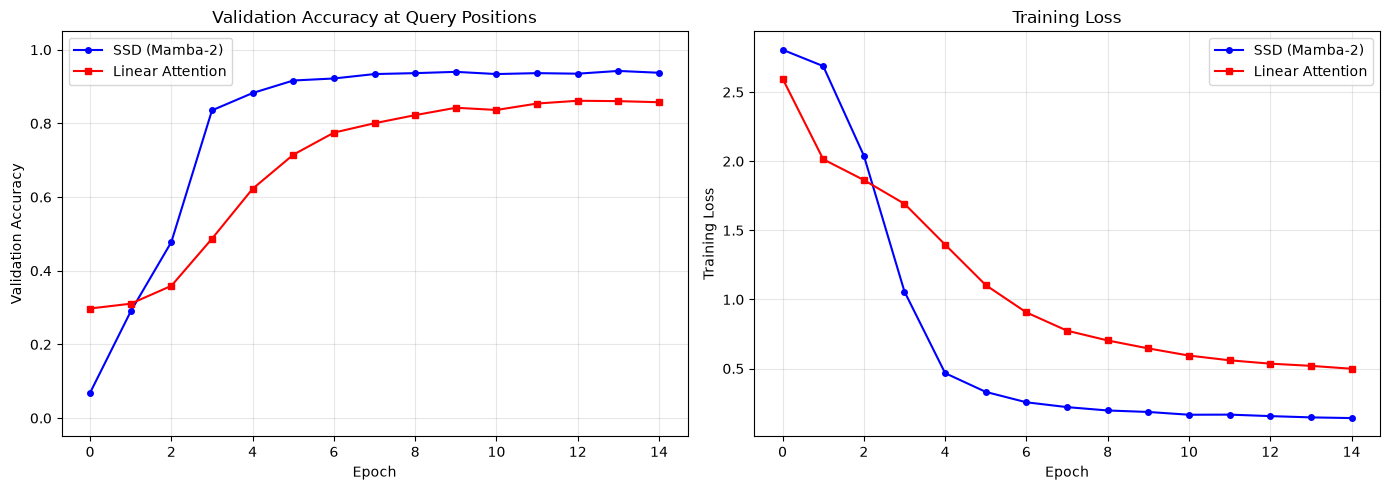

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation accuracy
axes[0].plot(ssd_history['val_acc'], 'b-o', label='SSD (Mamba-2)', markersize=4)
axes[0].plot(la_history['val_acc'], 'r-s', label='Linear Attention', markersize=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation Accuracy')
axes[0].set_title('Validation Accuracy at Query Positions')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(-0.05, 1.05)

# Training loss
axes[1].plot(ssd_history['loss'], 'b-o', label='SSD (Mamba-2)', markersize=4)
axes[1].plot(la_history['loss'], 'r-s', label='Linear Attention', markersize=4)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Training Loss')
axes[1].set_title('Training Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Final Evaluation

Accuracy is measured only at **query positions** - the tokens where the model must recall
a previously-seen value. A random baseline scores about 1/8 = 0.125 (8 possible values per query).


In [11]:
# Final comparison table
print(f"{'Model':<20} {'Val Accuracy':>14} {'Parameters':>12} {'Time (s)':>10}")
print('-' * 58)

results = []
for name, model, history, t in [
    ('SSD (Mamba-2)', model_ssd, ssd_history, ssd_time),
    ('Linear Attention', model_la, la_history, la_time),
]:
    acc = history['val_acc'][-1]
    n = sum(p.numel() for p in model.parameters())
    print(f'{name:<20} {acc:>14.4f} {n:>12,} {t:>10.1f}')
    results.append((name, acc, n, t))

print('-' * 58)
print(f'Random baseline: ~{1/8:.3f} (1 of 8 possible values per query)')
print()
ssd_acc = ssd_history['val_acc'][-1]
la_acc = la_history['val_acc'][-1]
print(f'SSD final accuracy: {ssd_acc:.4f}')
print(f'Linear attention final accuracy: {la_acc:.4f}')
print(f'SSD advantage: {ssd_acc - la_acc:+.4f}')


Model                  Val Accuracy   Parameters   Time (s)
----------------------------------------------------------
SSD (Mamba-2)                0.9375       85,008       13.0
Linear Attention             0.8575       35,344       17.0
----------------------------------------------------------
Random baseline: ~0.125 (1 of 8 possible values per query)

SSD final accuracy: 0.9375
Linear attention final accuracy: 0.8575
SSD advantage: +0.0800


## 12. Accuracy Bar Chart

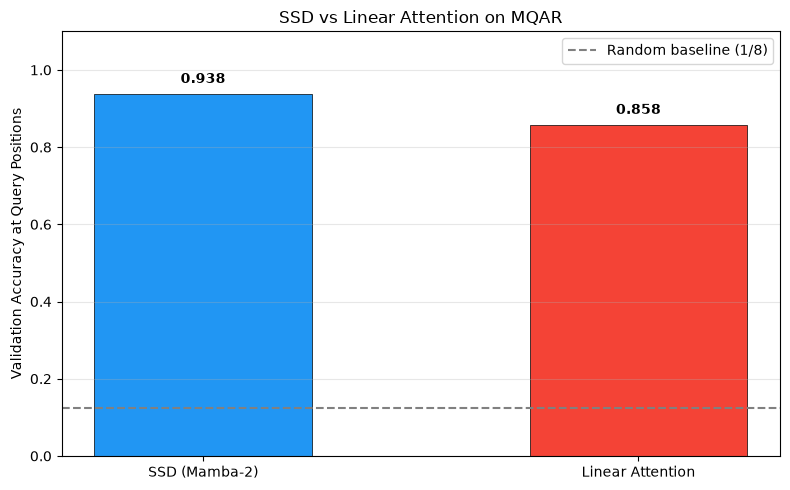

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

names = [r[0] for r in results]
accs = [r[1] for r in results]
colors = ['#2196F3', '#F44336']

bars = ax.bar(names, accs, color=colors, width=0.5, edgecolor='black', linewidth=0.5)
ax.axhline(y=1/8, color='gray', linestyle='--', label='Random baseline (1/8)')
ax.set_ylabel('Validation Accuracy at Query Positions')
ax.set_title('SSD vs Linear Attention on MQAR')
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 13. Duality Check Visualization

Bar chart showing the max absolute difference between quadratic and chunked SSD forms,
confirming the numerical equivalence that underpins the SSD framework. We use double
precision (float64) to isolate the theoretical duality from float32 accumulation noise.


T=32, P=4, N=8, blk=8: max_diff=7.55e-15
T=64, P=8, N=16, blk=16: max_diff=2.84e-14
T=128, P=16, N=32, blk=32: max_diff=8.53e-14


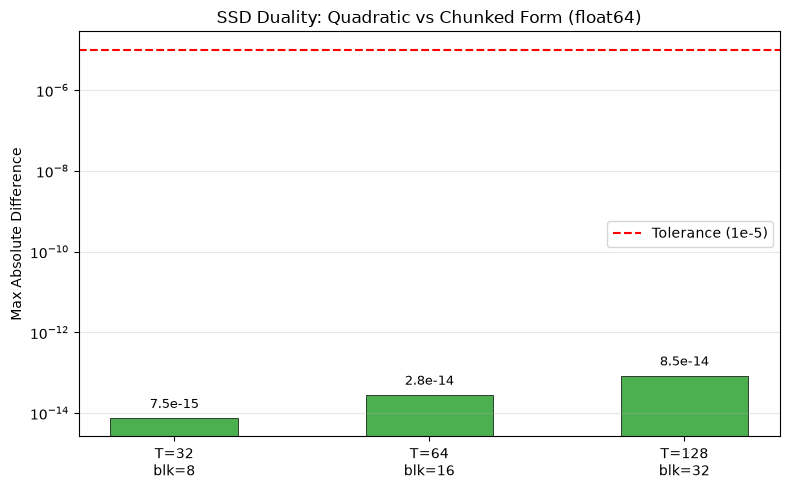

In [13]:
# Run duality check at multiple scales using float64
scales = [(32, 4, 8, 8), (64, 8, 16, 16), (128, 16, 32, 32)]
diffs = []
labels = []

for T_t, P_t, N_t, blk in scales:
    torch.manual_seed(42)
    X_t = torch.randn(T_t, P_t, dtype=torch.float64)
    A_t = torch.randn(T_t, dtype=torch.float64) * 0.1
    B_t = torch.randn(T_t, N_t, dtype=torch.float64)
    C_t = torch.randn(T_t, N_t, dtype=torch.float64)
    
    Y_q = ssd_quadratic(X_t, A_t, B_t, C_t)
    Y_c = ssd_chunked(X_t, A_t, B_t, C_t, block_len=blk)
    diff = (Y_q - Y_c).abs().max().item()
    diffs.append(diff)
    labels.append(f'T={T_t}\nblk={blk}')
    print(f'T={T_t}, P={P_t}, N={N_t}, blk={blk}: max_diff={diff:.2e}')

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, diffs, color='#4CAF50', width=0.5, edgecolor='black', linewidth=0.5)
ax.axhline(y=1e-5, color='red', linestyle='--', label='Tolerance (1e-5)')
ax.set_ylabel('Max Absolute Difference')
ax.set_title('SSD Duality: Quadratic vs Chunked Form (float64)')
ax.set_yscale('log')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bar, d in zip(bars, diffs):
    ax.text(bar.get_x() + bar.get_width()/2, d * 1.5,
            f'{d:.1e}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


## Summary

### What we built
- **SSD quadratic form** (Section 5, Eq. 16): the attention-like view where a selective SSM is
  $Y = (L \circ CB^T) X$ with a 1-semiseparable mask $L = \exp(\text{segsum}(A))$
- **SSD chunked form** (Listing 1): the block-decomposed algorithm combining matmul-friendly
  diagonal blocks with a smaller inter-chunk recurrence - $O(TN^2)$, matmul-dominated
- **Duality verification**: numerical proof that the two forms produce identical outputs (max diff < 1e-12 in float64)
- **Learnable SSD layer** wrapped in Mamba-2 residual blocks, trained on MQAR
- **Linear attention baseline** (SSD with $A=0$) for comparison

### What the run above shows
- The quadratic and chunked SSD forms are numerically identical, confirming the duality
- The SSD layer's input-dependent decay (scalar A) lets it selectively remember/forget,
  outperforming standard linear attention on associative recall
- Trained for **15 epochs** with AdamW (lr=1e-3) on 4000 synthetic MQAR examples

### Simplifications vs the paper
- 2 layers, 64 dim, ~85K params (paper: 48+ layers, 2560 dim, 2.7B params)
- Synthetic MQAR at L=64, 16-token vocab, 4 key-value pairs (paper: Pile, 300B tokens)
- Pure PyTorch einsum (paper: custom CUDA/Triton kernels)
- No tensor parallelism or FlashAttention-style fusion

The advantage of SSD's hardware efficiency (2-8x over Mamba-1's scan) is most pronounced at
large state sizes (N=64-256) and long sequences (2K-16K) where the block decomposition exploits
GPU matmul units - not measurable in this toy setting.
